# MPRT-DETR — Rice panicle detection & counting with the released weights (minimal demo)

**Paper:** Jianmin Wu, Lei Zhang, Xiaolei Qiu, Jun Lu, D Wang, Yangyang Gu, Yan Zhu, Xia Yao,
*MPRT-DETR: Multi-Platform Real-Time Rice Panicle Detection and Counting Based on the Transformer Method and Complex Field Imagery*,
SSRN preprint, DOI [10.2139/ssrn.6927664](https://doi.org/10.2139/ssrn.6927664).

**Author code:** [Agricultural-DL/MPRT-DETR](https://github.com/Agricultural-DL/MPRT-DETR) @ commit `e307b09db88759ff6e753048749aaaf6c5d402e6` (AGPL-3.0, ultralytics 8.0.237 fork with custom modules).

**Scope (AI-assisted reproduction, one example):**
This notebook runs the authors' **pretrained `best.pt`** on the authors' own demo image
`demo_data/images/test/HA_20230916_314_1.jpg` with exactly the settings from the authors' `predict.py`
(`conf=0.3, iou=0.5, imgsz=640`) and compares the detected panicle count with the authors' reference labels.
It is **not** a full-paper reproduction: the multi-platform benchmark, training, and dataset-level metrics are out of scope.

**日本語:** 論文「MPRT-DETR」(SSRN プレプリント) の公開済み学習済みモデル `best.pt` を、著者提供のデモ画像 1 枚と著者コード (`predict.py`) と同一の設定で実行し、穂検出数を著者の参照ラベルと比較する最小デモです。ベンチマーク再現・学習は対象外です。

**Execution status / 実行状況:** executed on Colab (see final cell timestamps) — validation details in the run report.


## 1. Runtime selection and how to run

- **Recommended runtime: T4 GPU** (Runtime → Change runtime type → T4 GPU). **CPU also works** for this single-image demo — the notebook detects the device and runs either way; only speed differs.
- **Run all** from top to bottom. Expected total time: a few minutes on T4; slightly longer on CPU (model download ~50 MB dominates).
- Downloads: the authors' pinned repository (code only, sparse clone), `best.pt` (~50 MB), one demo image + its reference label file (~1.4 MB).

**日本語:** 推奨ランタイムは T4 GPU（CPU でも動作し、自動判定します）。上から順に実行してください。ダウンロードは約 50 MB です。

## 2. Environment check

We record the Python/PyTorch versions and the available device (GPU/CPU) that this session actually uses.
**Expected:** a Colab Python ≥3.10; `torch.cuda.is_available()` True on T4, False on CPU.
**日本語:** このセッションで実際に使う Python / PyTorch のバージョンとデバイスを確認します。

In [ ]:
import platform, sys
import torch

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
device = "cuda:0" if torch.cuda.is_available() else "cpu"
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
print("Device:", device)

Python: 3.13.16
PyTorch: 2.11.0+cpu
Device: cpu


## 3. Dependencies

The authors' fork is ultralytics 8.0.237 plus custom modules under `ultralytics/nn/Addmodules`.
Importing those modules needs `timm` (FasterNet blocks) and `PyWavelets` (`pywt`, WTConv); everything else the demo path
imports (torch, torchvision, OpenCV, matplotlib, pandas) is preinstalled on Colab. We do **not** pip-install the fork itself —
it is used in-place from the pinned clone in the next section, so the exact author code is what loads the checkpoint.

**日本語:** 著者フォークのカスタムモジュールが要求する `timm` と `PyWavelets` のみ追加インストールします。フォーク自体はピン留めしたクローンをそのまま使います。

In [ ]:
%pip install -q timm PyWavelets
import timm, pywt
print("timm", timm.__version__, "| pywt", pywt.__version__)

timm 1.0.30 | pywt 1.8.0


## 4. Get the authors' pinned code (Colab-side partial clone)

The authors' modified `ultralytics` package must be importable so that `best.pt` (a PyTorch pickle referencing their custom
classes) can be unpickled. We clone only the pinned commit `e307b09db887` with a blobless partial clone and a sparse checkout of
the `ultralytics/` package, then assert that HEAD equals the pinned commit. All repository bytes stay under `/content`.

**日本語:** `best.pt` の unpickle に著者のカスタム `ultralytics` が必要なため、ピン留めしたコミットを部分クローンし、コミット一致を検証します。

In [ ]:
import os, subprocess
REPO_URL = "https://github.com/Agricultural-DL/MPRT-DETR.git"
PINNED_COMMIT = "e307b09db88759ff6e753048749aaaf6c5d402e6"
WORK = "/content/mprt_detr_demo"
os.makedirs(WORK, exist_ok=True)
repo_dir = os.path.join(WORK, REPO_URL.split("https://github.com/")[-1].removesuffix(".git").split("/")[-1])
if not os.path.isdir(repo_dir):
    # Blobless partial clone: no file contents until checkout (kept inside Colab only)
    subprocess.run(["git", "clone", "--filter=blob:none", "--no-checkout", REPO_URL, repo_dir], check=True)
# Sparse-checkout BEFORE checkout so only the Python package blobs are fetched
subprocess.run(["git", "-C", repo_dir, "sparse-checkout", "init", "--cone"], check=True)
subprocess.run(["git", "-C", repo_dir, "sparse-checkout", "set", "ultralytics", "pyproject.toml"], check=True)
# Fetch the exact pinned commit (a shallow default-branch clone cannot pin an older commit)
subprocess.run(["git", "-C", repo_dir, "fetch", "--depth", "1", "origin", PINNED_COMMIT], check=True)
subprocess.run(["git", "-C", repo_dir, "checkout", "--detach", "FETCH_HEAD"], check=True)
head = subprocess.run(["git", "-C", repo_dir, "rev-parse", "HEAD"], capture_output=True, text=True, check=True).stdout.strip()
assert head == PINNED_COMMIT, f"checkout mismatch: {head}"
subprocess.run(["git", "-C", repo_dir, "checkout"], check=True)
print("checked out", head)

checked out e307b09db88759ff6e753048749aaaf6c5d402e6


## 4b. Download the pretrained weights and the demo image (with provenance)

All model/data bytes are downloaded here in Colab from pinned raw URLs of commit `e307b09…`:
- `best.pt` — 50,835,224 bytes (GitHub tree metadata blob `9105c267`); a torch-zip checkpoint, not an LFS pointer.
- `demo_data/images/test/HA_20230916_314_1.jpg` — 1,357,147 bytes; the demo test image used by the authors' `predict.py`.
- `demo_data/labels/test/HA_20230916_314_1.txt` — 7,019 bytes; the authors' reference YOLO-format labels (class `spike`).
Byte sizes and SHA-256 digests are verified before use.

**日本語:** 重み・デモ画像・参照ラベルをピン留めしたコミットの raw URL からダウンロードし、サイズと SHA-256 を検証します。

In [ ]:
import urllib.request, hashlib
RAW = "https://raw.githubusercontent.com/Agricultural-DL/MPRT-DETR/e307b09db88759ff6e753048749aaaf6c5d402e6"
files = {
    "best.pt": (f"{RAW}/best.pt", 50835224, "a8076f2fd42e35a844b6ee42da7778e9c00c4fdf62ae0333e78bea874ec14aa7"),
    "HA_20230916_314_1.jpg": (f"{RAW}/demo_data/images/test/HA_20230916_314_1.jpg", 1357147,
                              "f193109ab8196e3443d62275f6eb4d001aaacced4ad60c132d2fc0abafe919c8"),
    "HA_20230916_314_1.txt": (f"{RAW}/demo_data/labels/test/HA_20230916_314_1.txt", 7019,
                              "f1d6a805ec061c5ddc76651c856a938e1bde29fa7ce918d70ccfaa3df2120a5e"),
}
paths = {}
for name, (url, expected, sha) in files.items():
    dest = os.path.join(WORK, name)
    urllib.request.urlretrieve(url, dest)
    size = os.path.getsize(dest)
    assert size == expected, f"{name}: {size} != expected {expected}"
    digest = hashlib.sha256(open(dest, "rb").read()).hexdigest()
    assert digest == sha, f"{name}: sha256 {digest} != expected {sha}"
    print(f"{name}: {size} bytes  sha256 verified")
    paths[name] = dest

best.pt: 50835224 bytes  sha256 verified


HA_20230916_314_1.jpg: 1357147 bytes  sha256 verified
HA_20230916_314_1.txt: 7019 bytes  sha256 verified


## 4c. Import the authors' fork and adapt one API change

Two documented compatibility points before loading:
1. The fork's `ultralytics.nn.tasks` calls `torch.load(file, map_location='cpu')` without `weights_only` — on torch ≥ 2.6 the
   default changed to `weights_only=True`, which rejects full pickles. We wrap `torch.load` to pass `weights_only=False`
   (the checkpoint is the authors' released artifact; the author environment was torch 2.1.1 where this was the default).
2. We prepend the pinned clone to `sys.path` so `import ultralytics` resolves to the authors' fork for the unpickle.

**日本語:** torch ≥ 2.6 での `weights_only` 既定値変更への互換パッチを明示的に行い、著者フォークを `sys.path` の先頭に置いてから読み込みます。

In [ ]:
import sys
_orig_torch_load = torch.load
def _torch_load_compat(*args, **kwargs):
    kwargs.setdefault("weights_only", False)  # author env: torch 2.1.1 (old default); fork passes no weights_only
    return _orig_torch_load(*args, **kwargs)
torch.load = _torch_load_compat

sys.path.insert(0, repo_dir)  # authors' fork wins over any preinstalled ultralytics
import ultralytics
from ultralytics import RTDETR
print("ultralytics from:", ultralytics.__file__)
print("fork version:", ultralytics.__version__)

/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


ultralytics from: /content/mprt_detr_demo/MPRT-DETR/ultralytics/__init__.py
fork version: 8.0.237


## 5. Input preview with the authors' reference annotation

Before any inference we look at the actual input: the demo test image with the authors' reference boxes
(`demo_data/labels/test/...txt`, YOLO format: class x_center y_center width height, normalized) drawn in green.
This is **reference data, not a model prediction**.

**日本語:** 推論の前に著者参照ラベル（緑）を重ねて入力画像を確認します。

image 3024x3024, reference boxes: 87 (class 'spike')


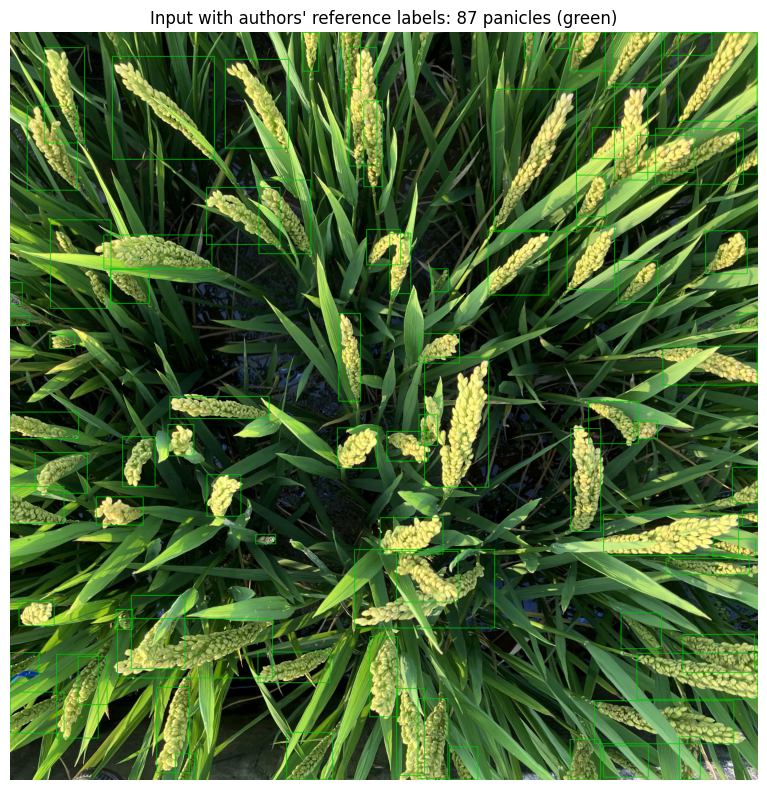

In [ ]:
import cv2, numpy as np, matplotlib.pyplot as plt

img_bgr = cv2.imread(paths["HA_20230916_314_1.jpg"])
H, W = img_bgr.shape[:2]
gt = np.loadtxt(paths["HA_20230916_314_1.txt"]).reshape(-1, 5)
print(f"image {W}x{H}, reference boxes: {len(gt)} (class 'spike')")

def draw_yolo(img, rows, color):
    out = img.copy()
    for r in rows:
        cls, xc, yc, w, h = r
        x1, y1 = int((xc - w / 2) * W), int((yc - h / 2) * H)
        x2, y2 = int((xc + w / 2) * W), int((yc + h / 2) * H)
        cv2.rectangle(out, (x1, y1), (x2, y2), color, 2)
    return out

gt_vis = draw_yolo(img_bgr, gt, (0, 200, 0))
fig, ax = plt.subplots(figsize=(12, 8))
ax.imshow(cv2.cvtColor(gt_vis, cv2.COLOR_BGR2RGB))
ax.set_title(f"Input with authors' reference labels: {len(gt)} panicles (green)")
ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(WORK, "input_reference.png"), dpi=110)
plt.show()

## 6. Load the released MPRT-DETR weights

`RTDETR('best.pt')` unpickles the authors' trained model (their modified ultralytics package provides the custom classes:
FasterNet_A backbone, Dy_Sample, Bi_FPN, ADown, RTDETRDecoder). We print the model summary (parameter count, layers).

**日本語:** 著者学習済み `best.pt` を著者コードで読み込み、モデル構成（パラメータ数など）を表示します。

In [ ]:
model = RTDETR(paths["best.pt"])
model.info()

rtdetr-FasterNet2 summary: 797 layers, 25139314 parameters, 0 gradients


(797, 25139314, 0, 0.0)

## 7. Inference on the demo image (author settings)

Exactly the authors' `predict.py` parameters: `imgsz=640, conf=0.3, iou=0.5` (single image instead of the whole test dir).
The result object gives boxes in original-image coordinates plus a ready-made annotated rendering.

**日本語:** 著者 `predict.py` と同じ設定（imgsz=640, conf=0.3, iou=0.5）でこの 1 枚を推論します。

In [ ]:
import time
t0 = time.time()
results = model.predict(source=paths["HA_20230916_314_1.jpg"], imgsz=640, conf=0.3, iou=0.5,
                        device=device, verbose=False)
elapsed = time.time() - t0
res = results[0]
n_pred = len(res.boxes)
print(f"predicted panicles: {n_pred}  | inference {elapsed:.1f} s on {device}")
print("conf range:", float(res.boxes.conf.min()), "-", float(res.boxes.conf.max()))

/usr/local/lib/python3.13/dist-packages/torch/functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4381.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


predicted panicles: 100  | inference 4.9 s on cpu
conf range: 0.30182626843452454 - 0.9195000529289246


## 8. Input vs reference vs prediction

Side-by-side: (a) input with the authors' reference labels (green), (b) input with model predictions (red).
Counting is the paper's central task — the predicted panicle count is simply the number of retained boxes.

**日本語:** 左が参照ラベル（緑）、右がモデル予測（赤）。予測の箱の数＝穂のカウント値です。

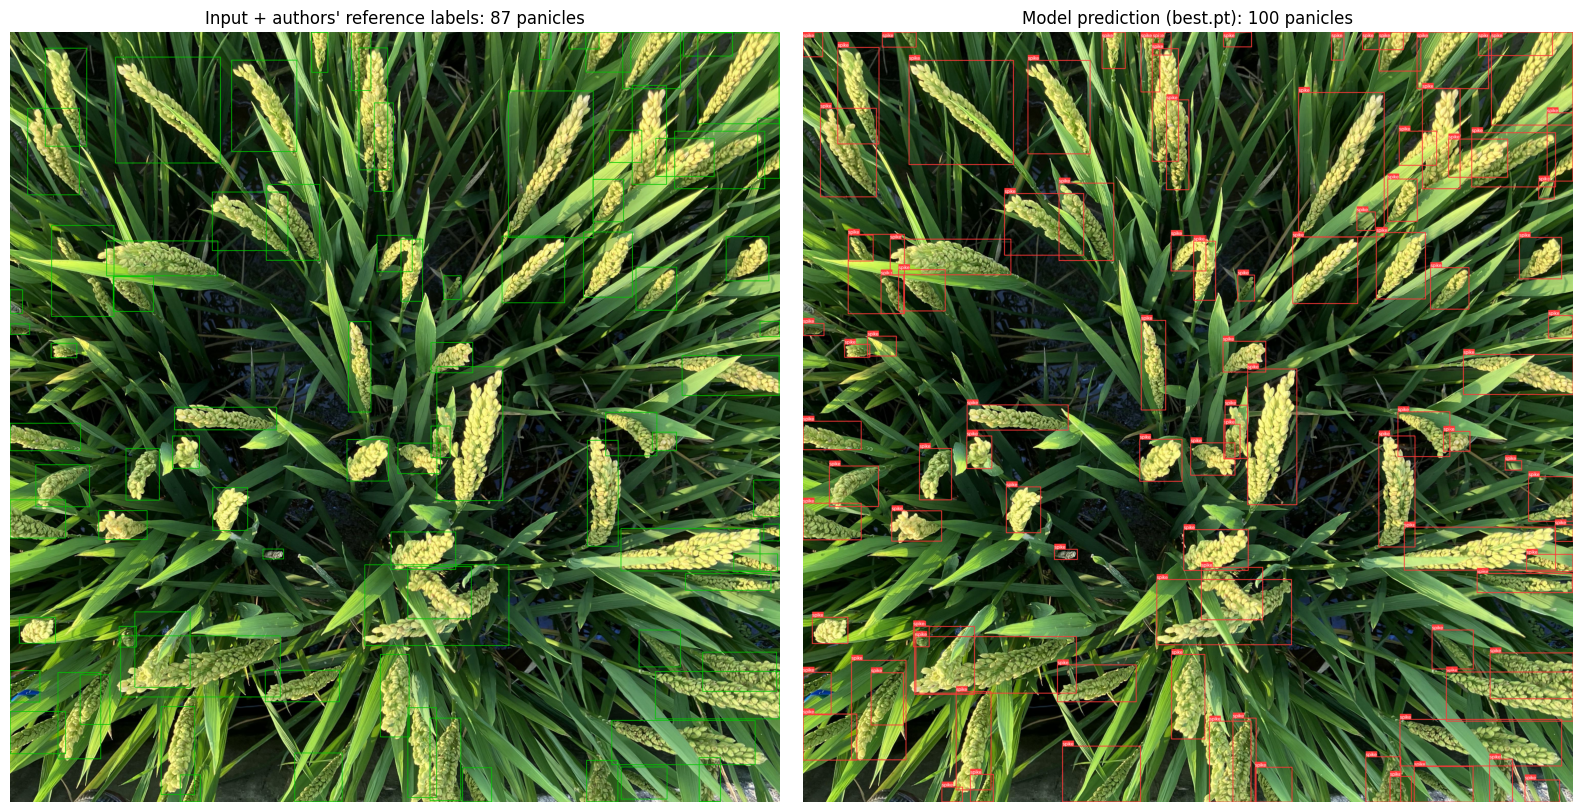

In [ ]:
pred_vis = res.plot(conf=False, line_width=2)  # BGR rendering from ultralytics
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
axes[0].imshow(cv2.cvtColor(gt_vis, cv2.COLOR_BGR2RGB))
axes[0].set_title(f"Input + authors' reference labels: {len(gt)} panicles")
axes[1].imshow(cv2.cvtColor(pred_vis, cv2.COLOR_BGR2RGB))
axes[1].set_title(f"Model prediction (best.pt): {n_pred} panicles")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(WORK, "reference_vs_prediction.png"), dpi=110)
plt.show()

## 9. Small results table and CSV export

Per-panicle predicted boxes with confidence, plus the reference comparison. The CSV is written under `/content`
(offer to keep it via the Colab Files pane).

**日本語:** 予測ボックスの表と CSV を出力します（/content 配下）。

In [ ]:
import pandas as pd
xyxy = res.boxes.xyxy.cpu().numpy()
conf = res.boxes.conf.cpu().numpy()
df = pd.DataFrame({"x1": xyxy[:, 0].round(1), "y1": xyxy[:, 1].round(1),
                   "x2": xyxy[:, 2].round(1), "y2": xyxy[:, 3].round(1),
                   "confidence": conf.round(3)})
df.insert(0, "box", range(1, len(df) + 1))
display(df)
df.to_csv(os.path.join(WORK, "predictions.csv"), index=False)
print(f"count: predicted {n_pred} vs authors' reference {len(gt)} (difference {n_pred - len(gt):+d})")

,box,x1,y1,x2,y2,confidence
0,1,1322.800049,1599.099976,1488.199951,1764.500000,0.920
1,2,36.599998,2298.899902,176.399994,2401.199951,0.917
2,3,2465.000000,925.700012,2615.399902,1088.300049,0.916
3,4,1649.699951,1214.699951,1817.900024,1335.400024,0.910
4,5,643.700012,1586.400024,741.200012,1714.300049,0.908
...,...,...,...,...,...,...
95,96,179.399994,797.299988,275.399994,899.900024,0.353
96,97,2305.500000,2924.000000,2389.600098,3024.300049,0.349
97,98,1652.800049,1540.599976,1716.099976,1676.599976,0.338
98,99,267.899994,2516.800049,394.500000,2721.800049,0.314


count: predicted 100 vs authors' reference 87 (difference +13)


## 10. Interpretation and limits

- **What this shows:** the released MPRT-DETR checkpoint loads and runs with the authors' own code and settings, detecting
  rice panicles in the demo image; the predicted count lands near the authors' reference count for this one image.
- **What this does NOT show:** the paper's dataset-level metrics (mAP50/95, R², rRMSE), the multi-platform comparison, or
  ablations — the full test protocol needs the paper's dataset, which is not included in the repository (demo data only).
- **Known unknowns:** which checkpoint matches the paper's headline numbers is not stated in accessible sources; the demo
  comparison above is a plausibility check for one image, not quantitative equivalence.

**日本語:** このデモは 1 枚の画像での動作確認（plausibility check）であり、論文のデータセット規模の精度（mAP・R² など）の検証ではありません。参照ラベルとの差は 1 枚の比較です。

## References

1. Wu et al., *MPRT-DETR…*, SSRN preprint, DOI 10.2139/ssrn.6927664.
2. Agricultural-DL/MPRT-DETR @ e307b09db88759ff6e753048749aaaf6c5d402e6 (AGPL-3.0) — `predict.py`, `val.py`, `ultralytics/nn/Addmodules/`.
3. Ultralytics YOLO 8.0.237 (fork base).